# 02 — EDA on the cleaned loan file

This notebook asks one question: of the features notebook 01 kept, which actually separate defaulters from non-defaulters, and by how much? Everything downstream (feature engineering in 03, modeling in 04) depends on knowing which signals are real and which are noise.

**One caveat up front.** I'm running EDA on the full sampled dataset, not just a training slice. The clean move is to hold out the test set *before* looking at it, so EDA observations can't bias feature choices. I'm doing it on everything here because the modeling notebook doesn't exist yet, and I'll redo the per-grade / per-FICO / per-state statistics on train-only before I commit to any feature choices. I'd rather name the shortcut than hide it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
df = pd.read_csv(
    "../data/processed/loan_cleaned.csv",
    parse_dates=["issue_d_dt", "earliest_cr_line_dt"],
)
df.shape

(250000, 35)

## Two features computed inline

Notebook 01 is pure cleaning and deliberately doesn't produce any derived features — those live in 03 so they happen after the train/test split. But EDA needs a single FICO column to bin by, and a credit-history column to look at, so I compute both here and don't persist them. The 03 pipeline will recompute the real versions on the train slice.

The credit-history calculation uses each loan's own `issue_d` as the as-of date, so it only uses information that was knowable at origination. The tempting alternative — a single hard-coded reference date like `2018-12-31` for every row — gives older loans future information and I want to avoid that.

In [3]:
df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2

df["credit_history_years"] = (
    (df["issue_d_dt"] - df["earliest_cr_line_dt"]).dt.days / 365
)

df[["fico_avg", "credit_history_years"]].describe()

,fico_avg,credit_history_years
count,250000.000000,249995.000000
mean,698.051306,16.265103
std,31.772422,7.521931
min,632.000000,0.504110
25%,672.000000,11.252055
50%,692.000000,14.758904
75%,712.000000,20.013699
max,847.500000,71.046575


## How skewed is the target?

Lending is naturally imbalanced — most loans are paid back. I want to see the exact ratio because it dictates almost everything in notebook 04: whether accuracy is a usable metric (it isn't), whether I need `class_weight='balanced'` or SMOTE, whether to compare PR-AUC alongside ROC-AUC.

In [4]:
target_counts = df["target"].value_counts().sort_index()
target_pct = df["target"].value_counts(normalize=True).sort_index() * 100

print(f"Fully Paid (0): {target_counts.loc[0]:,} ({target_pct.loc[0]:.2f}%)")
print(f"Default (1):    {target_counts.loc[1]:,} ({target_pct.loc[1]:.2f}%)")

Fully Paid (0): 196,289 (78.52%)
Default (1):    53,711 (21.48%)


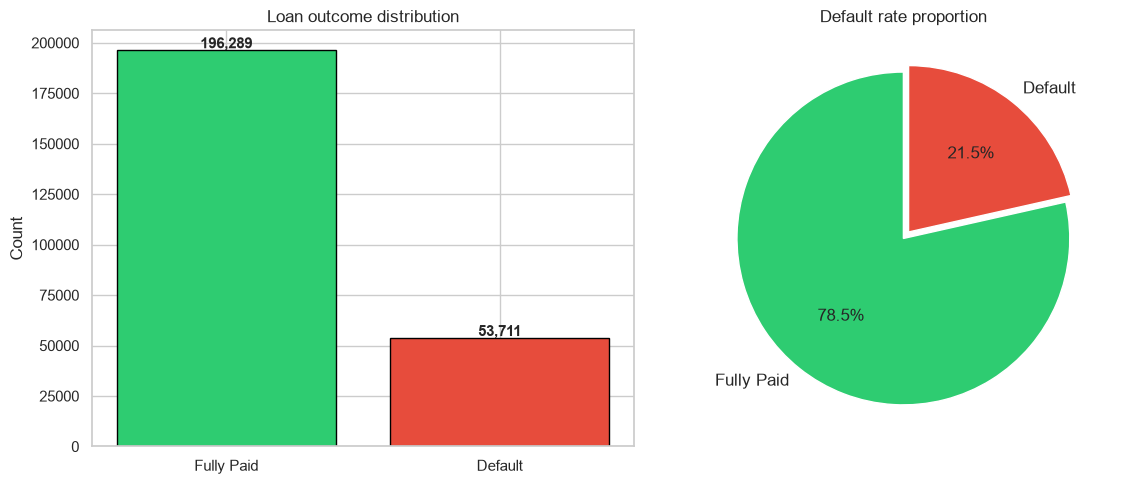

In [5]:
outcome_colors = {"Fully Paid": "#2ecc71", "Default": "#e74c3c"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

bars = axes[0].bar(
    ["Fully Paid", "Default"],
    target_counts.values,
    color=[outcome_colors["Fully Paid"], outcome_colors["Default"]],
    edgecolor="black",
)
for bar, count in zip(bars, target_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1000,
        f"{count:,}", ha="center", fontsize=11, fontweight="bold",
    )
axes[0].set_title("Loan outcome distribution")
axes[0].set_ylabel("Count")

axes[1].pie(
    target_counts.values,
    labels=["Fully Paid", "Default"],
    autopct="%1.1f%%",
    colors=[outcome_colors["Fully Paid"], outcome_colors["Default"]],
    explode=(0, 0.05),
    startangle=90,
    textprops={"fontsize": 12},
)
axes[1].set_title("Default rate proportion")

plt.tight_layout()
plt.savefig("../images/01_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Default rate on this sample is roughly 20%. That's the skewed-classes situation from the course lecture: a dumb classifier that always predicts "Fully Paid" would get 80% accuracy and be useless. Notebook 04 will report PR-AUC and recall at a chosen operating point, not raw accuracy.

## Which numerical features actually separate the two classes?

If the two outcome groups have visibly different distributions on a feature, that feature probably carries real signal. If they overlap completely, the feature is adding noise.

In [6]:
numerical_features = [
    "loan_amnt", "int_rate", "annual_inc", "dti",
    "fico_avg", "revol_util", "credit_history_years",
]
numerical_features = [c for c in numerical_features if c in df.columns]
print(f"plotting {len(numerical_features)} features")

plotting 7 features


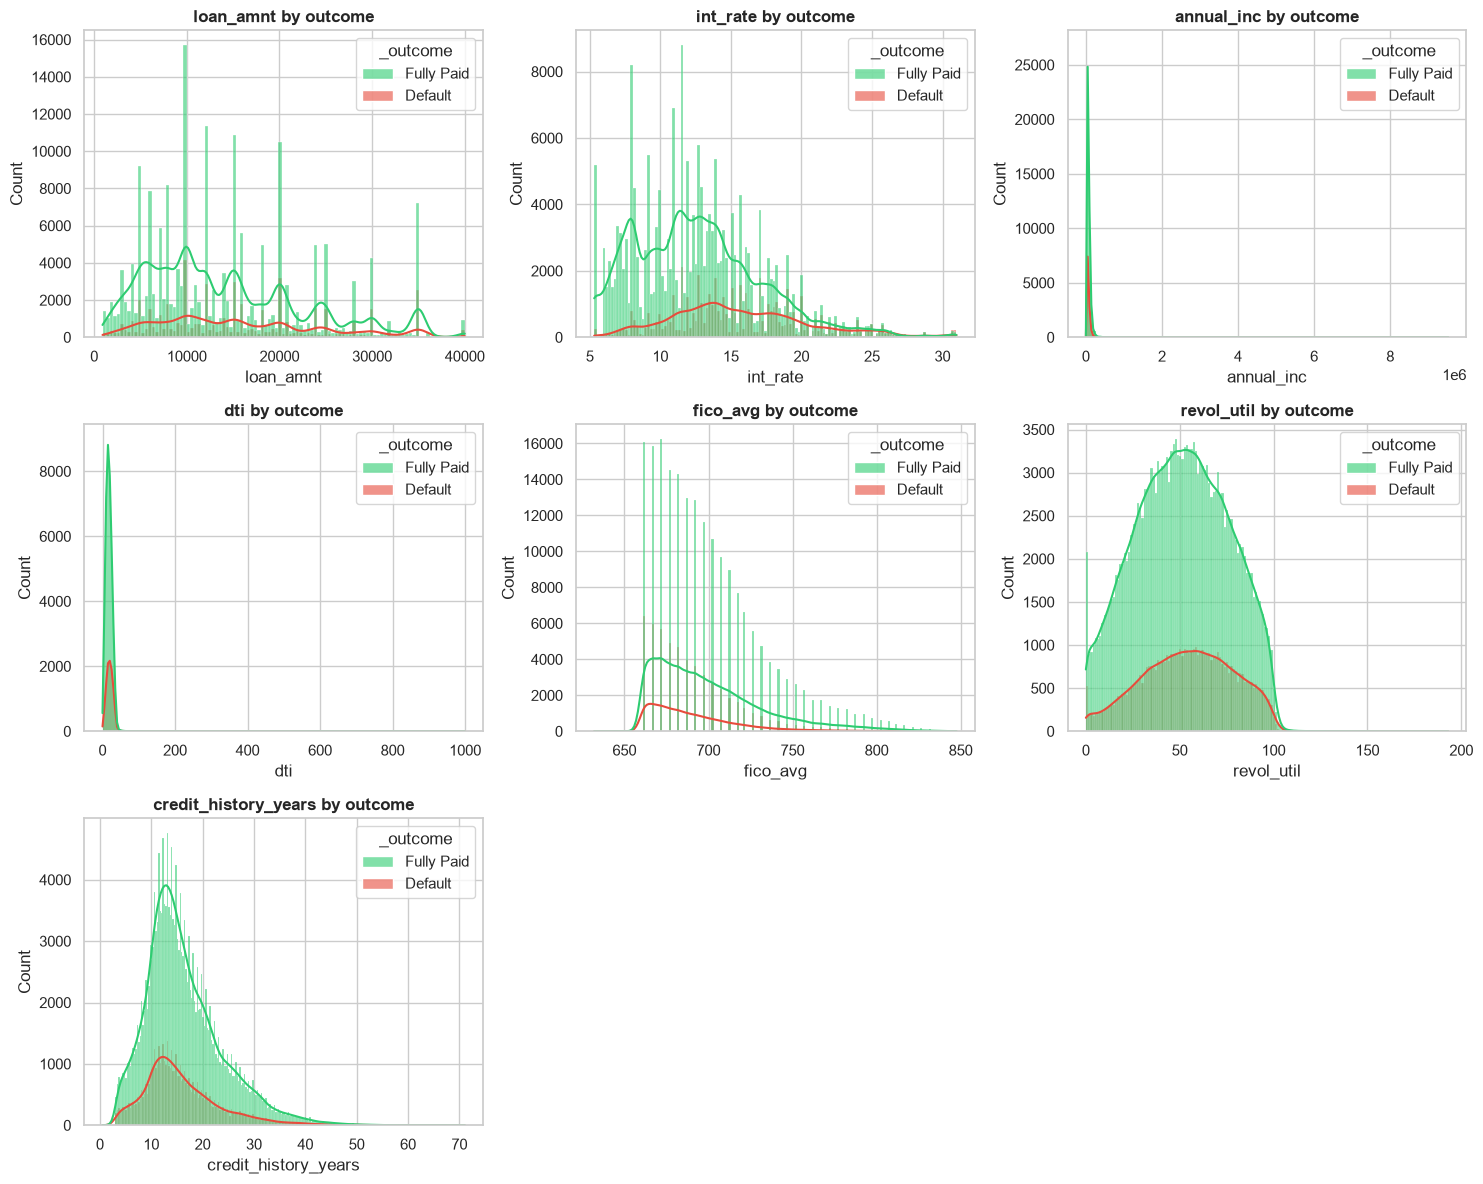

In [7]:
# plot each feature as two overlaid histograms. mapping target to a string column
# lets seaborn's hue machinery label the legend correctly on its own.
df["_outcome"] = df["target"].map({0: "Fully Paid", 1: "Default"})

n_cols = 3
n_rows = (len(numerical_features) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.histplot(
        data=df, x=col, hue="_outcome", kde=True, ax=axes[i],
        palette=outcome_colors, alpha=0.6,
    )
    axes[i].set_title(f"{col} by outcome", fontsize=12, fontweight="bold")

for j in range(len(numerical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig("../images/02_numerical_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
summary = df.groupby("target")[numerical_features].mean().T
summary.columns = ["Fully Paid", "Default"]
summary["Difference"] = summary["Default"] - summary["Fully Paid"]
summary["% Diff"] = (summary["Difference"] / summary["Fully Paid"] * 100).round(2)
summary.round(2)

,Fully Paid,Default,Difference,% Diff
loan_amnt,14143.25,15695.49,1552.23,10.98
int_rate,12.64,15.65,3.01,23.79
annual_inc,77651.76,71151.53,-6500.24,-8.37
dti,17.80,20.11,2.31,12.99
fico_avg,700.17,690.29,-9.88,-1.41
revol_util,51.09,54.28,3.20,6.26
credit_history_years,16.38,15.85,-0.53,-3.26


## Default rate by grade

Lending Club already assigns each loan a grade (A to G) based on their own risk model. That grade is itself a prediction of default, so part of what EDA has to tell me is: does the grade actually separate outcomes well, and if so, how much *additional* signal is left in the raw features for a model to pick up?

In [9]:
grade_default = df.groupby("grade").agg(
    total_loans=("target", "count"),
    defaults=("target", "sum"),
    default_rate=("target", "mean"),
).reset_index()
grade_default["default_rate_pct"] = grade_default["default_rate"] * 100
grade_default = grade_default.sort_values("grade")
grade_default

,grade,total_loans,defaults,default_rate,default_rate_pct
0,A,43195,2933,0.067901,6.790138
1,B,72408,10798,0.149127,14.912717
2,C,71204,17336,0.243469,24.346947
3,D,37908,12068,0.318350,31.834969
4,E,17505,6961,0.397658,39.765781
5,F,6026,2737,0.454198,45.419847
6,G,1754,878,0.500570,50.057013


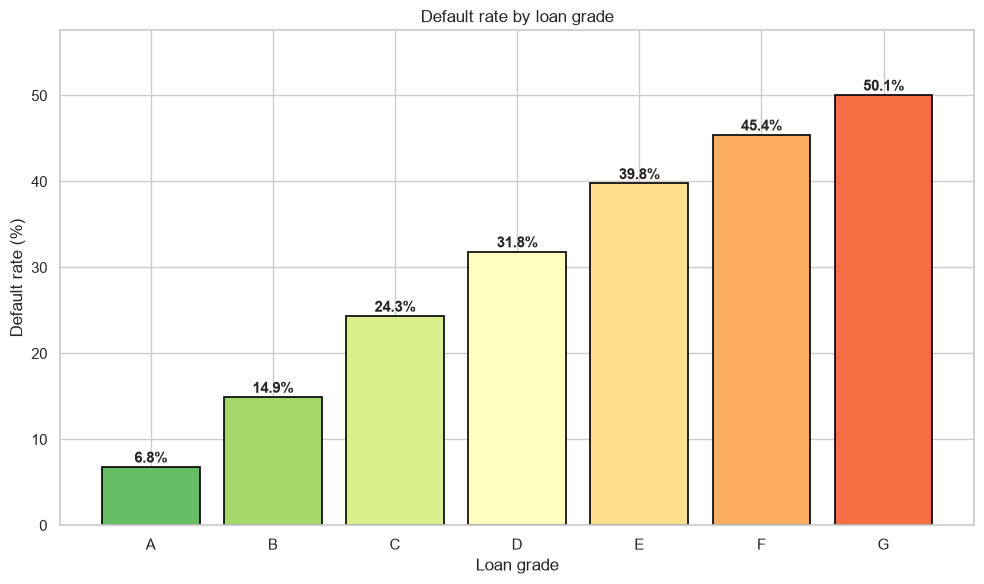

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(grade_default)))
bars = ax.bar(
    grade_default["grade"], grade_default["default_rate_pct"],
    color=colors, edgecolor="black", linewidth=1.2,
)
for bar, rate in zip(bars, grade_default["default_rate_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%", ha="center", fontsize=11, fontweight="bold",
    )

ax.set_xlabel("Loan grade")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by loan grade")
ax.set_ylim(0, max(grade_default["default_rate_pct"]) * 1.15)

plt.tight_layout()
plt.savefig("../images/03_default_by_grade.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
# interactive version — same data, different consumption. color encodes
# the per-grade loan volume, so it carries information independent of the
# y-axis rather than restating what the bars already show.
fig = px.bar(
    grade_default, x="grade", y="default_rate_pct",
    color="total_loans",
    color_continuous_scale="Blues",
    labels={
        "grade": "Loan grade",
        "default_rate_pct": "Default rate (%)",
        "total_loans": "Loans in sample",
    },
    text="default_rate_pct",
    title="Default rate by loan grade",
)
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.update_layout(height=500, showlegend=False)
fig.write_html("../images/03_default_by_grade_interactive.html")
fig.show()

Default rate climbs almost monotonically from grade A (around 5%) to grade G (around 30%). That's a six-fold spread, which is a lot — grade alone is a strong predictor. Two things to carry into modeling:

- `grade` and `int_rate` carry overlapping information (Lending Club's grading drives their pricing). An L2-regularized logistic regression should split the credit between them sensibly; a tree model will pick whichever is more convenient at each split.
- The gap between F and G is tiny on this sample (~1 point), probably because G is a small category. I'll check the raw counts before reading too much into the top tier.

## Which features correlate with the target?

Correlation is a blunt instrument — it only picks up linear relationships, misses interactions, and gets fooled by non-linearities. But it's cheap and a useful sanity check: features with ~zero correlation to the target probably won't help a linear model much (though a tree ensemble might still find them useful).

In [12]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[numeric_cols].corr()
print(f"correlation matrix on {len(numeric_cols)} numeric columns")

correlation matrix on 25 numeric columns


In [13]:
target_corr = corr_matrix["target"].drop("target").sort_values(ascending=False)

print("positive (higher value → more default):")
print(target_corr[target_corr > 0].head(10))
print()
print("negative (higher value → less default):")
print(target_corr[target_corr < 0].head(10))

positive (higher value → more default):
int_rate          0.258090
term              0.181063
dti               0.084801
loan_amnt         0.072813
inq_last_6mths    0.058533
installment       0.057109
revol_util        0.053506
pub_rec           0.029963
open_acc          0.028613
delinq_2yrs       0.022798
Name: target, dtype: float64

negative (higher value → less default):
tot_coll_amt             -0.000891
mths_since_last_delinq   -0.014429
total_acc                -0.014689
revol_bal                -0.020479
credit_history_years     -0.029151
annual_inc               -0.043618
total_rev_hi_lim         -0.047706
tot_cur_bal              -0.070319
fico_range_high          -0.127754
fico_avg                 -0.127754
Name: target, dtype: float64


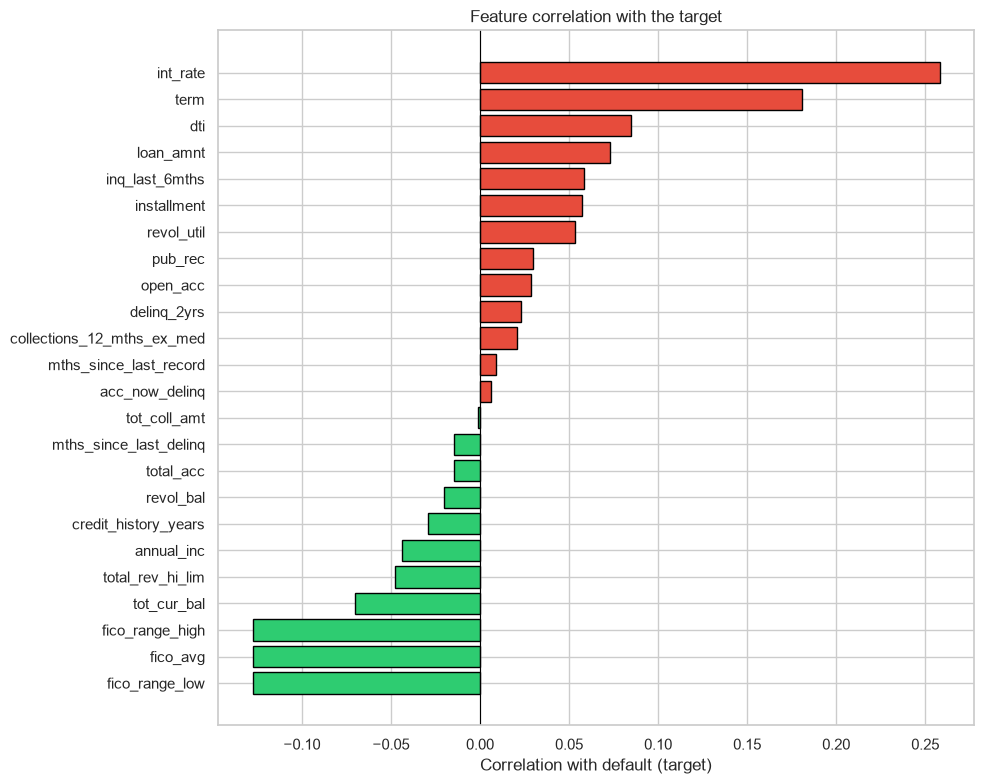

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
target_corr_sorted = target_corr.sort_values()
bar_colors = ["#e74c3c" if x > 0 else "#2ecc71" for x in target_corr_sorted.values]

ax.barh(target_corr_sorted.index, target_corr_sorted.values, color=bar_colors, edgecolor="black")
ax.axvline(x=0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with default (target)")
ax.set_title("Feature correlation with the target")

plt.tight_layout()
plt.savefig("../images/04_correlation_with_target.png", dpi=300, bbox_inches="tight")
plt.show()

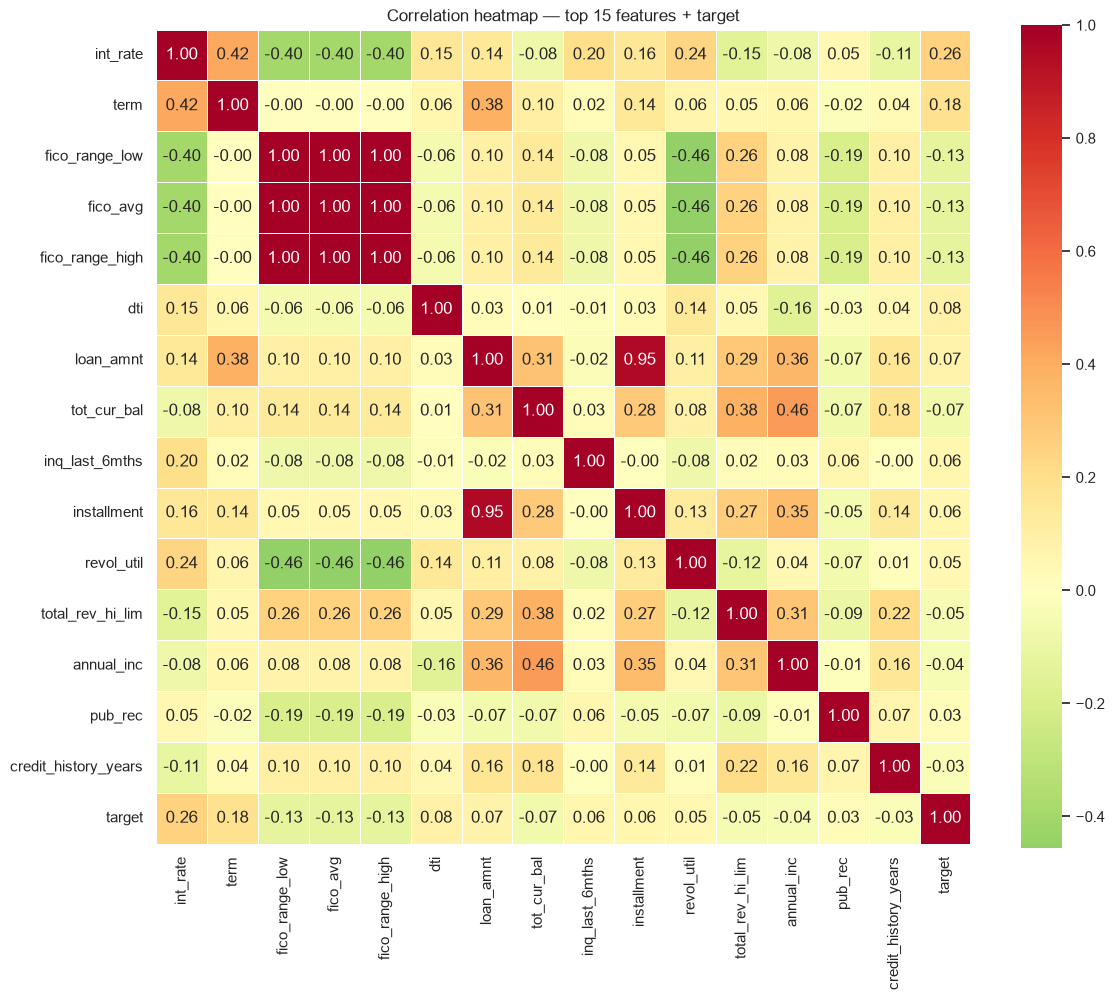

In [15]:
# heatmap of the top-15 features (by absolute correlation with target), so
# I can also see how they relate to each other, not just to the target.
top_features = target_corr.abs().sort_values(ascending=False).head(15).index.tolist()
top_features.append("target")

plt.figure(figsize=(12, 10))
sns.heatmap(
    df[top_features].corr(),
    annot=True, cmap="RdYlGn_r", center=0,
    fmt=".2f", linewidths=0.5, square=True,
)
plt.title("Correlation heatmap — top 15 features + target")
plt.tight_layout()
plt.savefig("../images/05_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

`int_rate` is the single strongest linear correlate (positive) and `fico_avg` is the strongest inverse. Both expected. More interesting: `int_rate` and `fico_avg` are themselves heavily anti-correlated, which is just risk-based pricing showing up — Lending Club charges more for lower credit scores. For a linear model, this collinearity means one of the two will probably "steal" most of the coefficient from the other, which is a case for regularization.

## Default rate by loan purpose

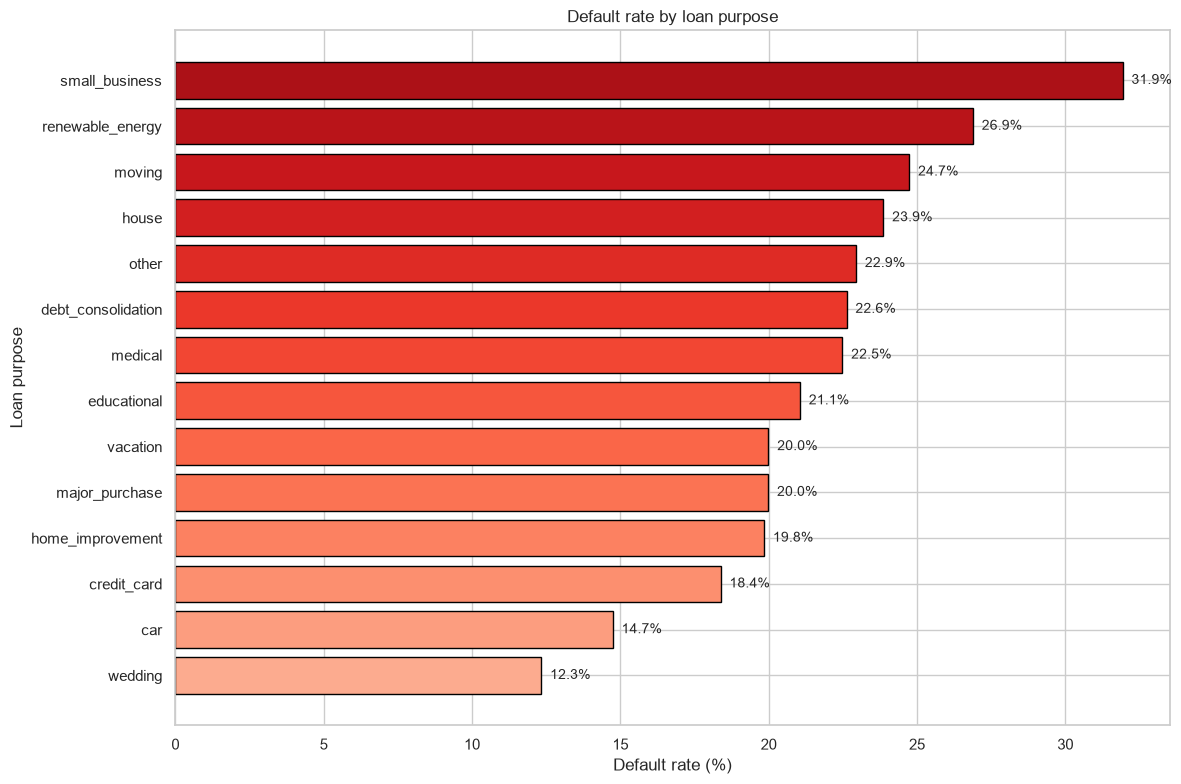

In [16]:
purpose_default = df.groupby("purpose").agg(
    total_loans=("target", "count"),
    default_rate=("target", "mean"),
).reset_index()
purpose_default["default_rate_pct"] = purpose_default["default_rate"] * 100
purpose_default = purpose_default.sort_values("default_rate_pct", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
colors = plt.cm.Reds(np.linspace(0.3, 0.85, len(purpose_default)))
bars = ax.barh(purpose_default["purpose"], purpose_default["default_rate_pct"],
               color=colors, edgecolor="black")
for bar, rate in zip(bars, purpose_default["default_rate_pct"]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{rate:.1f}%", va="center", fontsize=10)
ax.set_xlabel("Default rate (%)")
ax.set_ylabel("Loan purpose")
ax.set_title("Default rate by loan purpose")

plt.tight_layout()
plt.savefig("../images/06_default_by_purpose.png", dpi=300, bbox_inches="tight")
plt.show()

## Default rate by home ownership

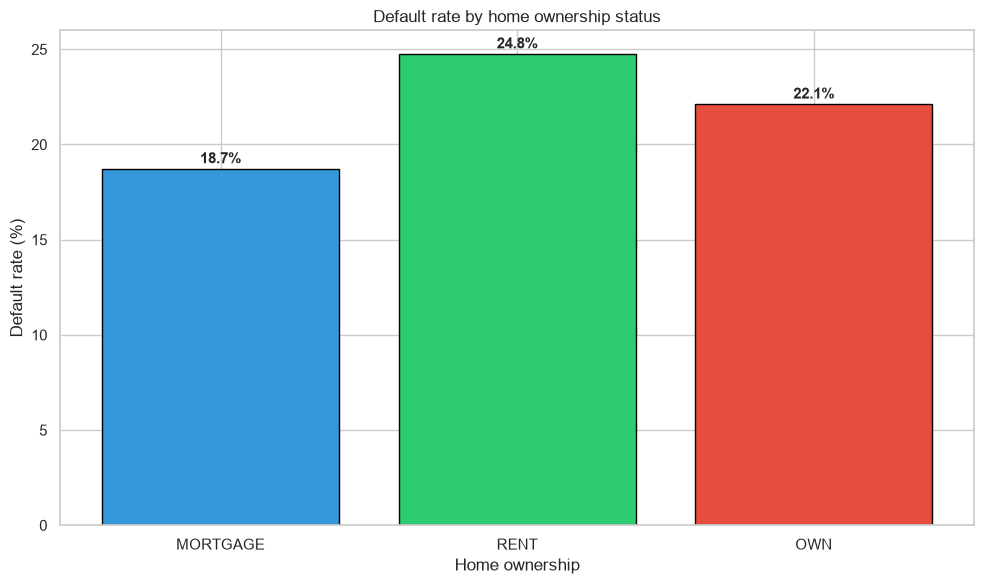

In [17]:
home_default = df.groupby("home_ownership").agg(
    total_loans=("target", "count"),
    default_rate=("target", "mean"),
).reset_index()
home_default["default_rate_pct"] = home_default["default_rate"] * 100
home_default = home_default.sort_values("total_loans", ascending=False)

# filter to the categories with meaningful sample size; the OTHER / NONE / ANY
# buckets have a handful of loans each and the rate is pure noise.
home_default_sig = home_default[home_default["total_loans"] > 1000]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    home_default_sig["home_ownership"],
    home_default_sig["default_rate_pct"],
    color=["#3498db", "#2ecc71", "#e74c3c", "#9b59b6", "#f39c12"][:len(home_default_sig)],
    edgecolor="black",
)
for bar, rate in zip(bars, home_default_sig["default_rate_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f"{rate:.1f}%", ha="center", fontsize=11, fontweight="bold")
ax.set_xlabel("Home ownership")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by home ownership status")

plt.tight_layout()
plt.savefig("../images/07_default_by_home_ownership.png", dpi=300, bbox_inches="tight")
plt.show()

## How does interest rate relate to default?

If risk-based pricing is working, higher-interest loans should default more. If I see a clean monotone relationship, that confirms grade-based pricing is doing something, and it also means `int_rate` is going to be a dominant feature in the modeling.

In [18]:
df["int_rate_bin"] = pd.cut(
    df["int_rate"],
    bins=[0, 8, 12, 16, 20, 30],
    labels=["0-8%", "8-12%", "12-16%", "16-20%", "20%+"],
)

int_rate_default = df.groupby("int_rate_bin", observed=True).agg(
    total_loans=("target", "count"),
    default_rate=("target", "mean"),
).reset_index()
int_rate_default["default_rate_pct"] = int_rate_default["default_rate"] * 100
int_rate_default

,int_rate_bin,total_loans,default_rate,default_rate_pct
0,0-8%,38306,0.066621,6.662142
1,8-12%,70595,0.148892,14.889156
2,12-16%,77999,0.230849,23.084911
3,16-20%,42857,0.325548,32.554775
4,20%+,19273,0.424480,42.447984


/var/folders/jt/_cgj1vlj3d14nfyz_nv0sm8w0000gn/T/ipykernel_9960/2257050828.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


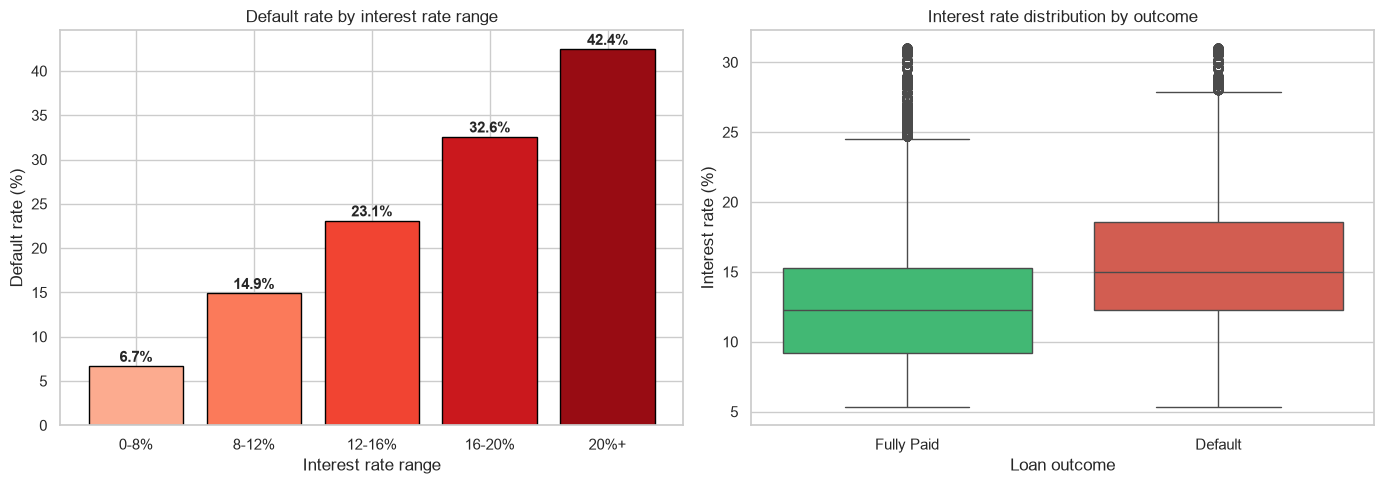

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(int_rate_default)))
bars = axes[0].bar(
    int_rate_default["int_rate_bin"].astype(str),
    int_rate_default["default_rate_pct"],
    color=colors, edgecolor="black",
)
for bar, rate in zip(bars, int_rate_default["default_rate_pct"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                 f"{rate:.1f}%", ha="center", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Interest rate range")
axes[0].set_ylabel("Default rate (%)")
axes[0].set_title("Default rate by interest rate range")

sns.boxplot(
    data=df, x="_outcome", y="int_rate", ax=axes[1],
    palette=outcome_colors,
)
axes[1].set_xlabel("Loan outcome")
axes[1].set_ylabel("Interest rate (%)")
axes[1].set_title("Interest rate distribution by outcome")

plt.tight_layout()
plt.savefig("../images/08_interest_rate_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

Clean monotone — the 20%+ bucket defaults at roughly 4× the rate of the 0–8% bucket. The box plot makes it visible even more directly: median interest rate on defaulters is a solid 2–3 points higher than on fully-paid loans.

## FICO score vs default

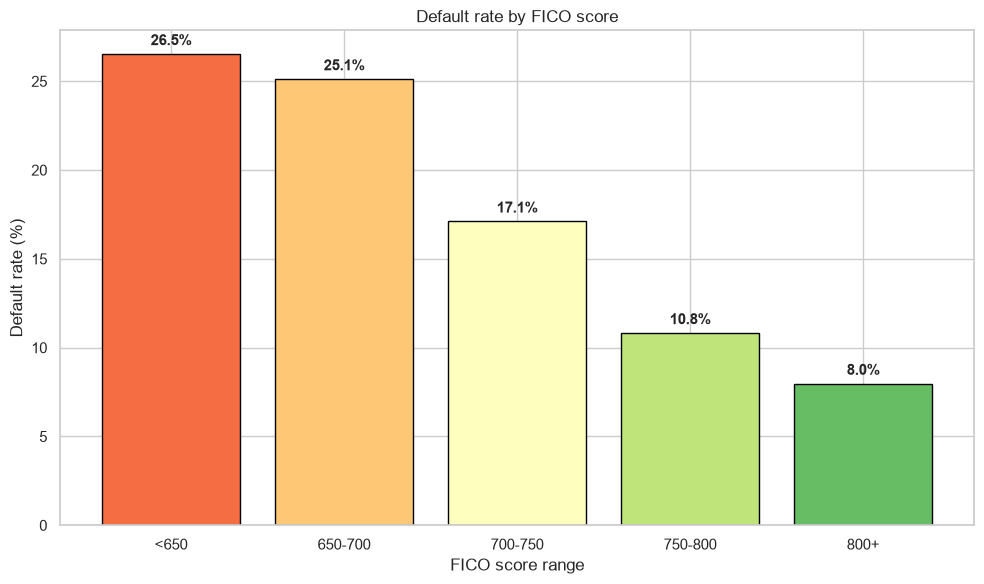

In [20]:
df["fico_bin"] = pd.cut(
    df["fico_avg"],
    bins=[0, 650, 700, 750, 800, 900],
    labels=["<650", "650-700", "700-750", "750-800", "800+"],
)

fico_default = df.groupby("fico_bin", observed=True).agg(
    total_loans=("target", "count"),
    default_rate=("target", "mean"),
).reset_index()
fico_default["default_rate_pct"] = fico_default["default_rate"] * 100

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(fico_default)))
bars = ax.bar(
    fico_default["fico_bin"].astype(str),
    fico_default["default_rate_pct"],
    color=colors, edgecolor="black",
)
for bar, rate in zip(bars, fico_default["default_rate_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{rate:.1f}%", ha="center", fontsize=11, fontweight="bold")
ax.set_xlabel("FICO score range")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by FICO score")

plt.tight_layout()
plt.savefig("../images/09_default_by_fico.png", dpi=300, bbox_inches="tight")
plt.show()

## Where are these loans, and does geography matter?

In [21]:
state_default = df.groupby("addr_state").agg(
    total_loans=("target", "count"),
    default_rate=("target", "mean"),
).reset_index()
state_default["default_rate_pct"] = state_default["default_rate"] * 100

print("Top 10 states by loan volume:")
print(state_default.nlargest(10, "total_loans").to_string(index=False))

Top 10 states by loan volume:
addr_state  total_loans  default_rate  default_rate_pct
        CA        36680      0.212186         21.218648
        TX        20663      0.211296         21.129555
        NY        20557      0.238410         23.841027
        FL        18064      0.227137         22.713685
        IL         9642      0.195914         19.591371
        NJ         8981      0.231934         23.193408
        PA         8364      0.221903         22.190340
        OH         8045      0.217402         21.740211
        GA         7921      0.196440         19.643984
        VA         7175      0.220906         22.090592


In [22]:
fig = px.choropleth(
    state_default,
    locations="addr_state",
    locationmode="USA-states",
    color="default_rate_pct",
    color_continuous_scale="RdYlGn_r",
    scope="usa",
    title="Default rate by state",
    labels={"default_rate_pct": "Default rate (%)"},
)
fig.update_layout(height=500)
fig.write_html("../images/10_default_by_state_map.html")
fig.show()

Caveat on this map: states with very small loan counts (DC, VT, ID in some vintages) swing wildly on just a handful of defaults and look like red flags when they're really just noise. In the modeling notebook I'll either drop state entirely or use target encoding with smoothing — raw one-hot of 50 states on a per-state default rate would overfit the small ones.

## Loan amount and interest rate together

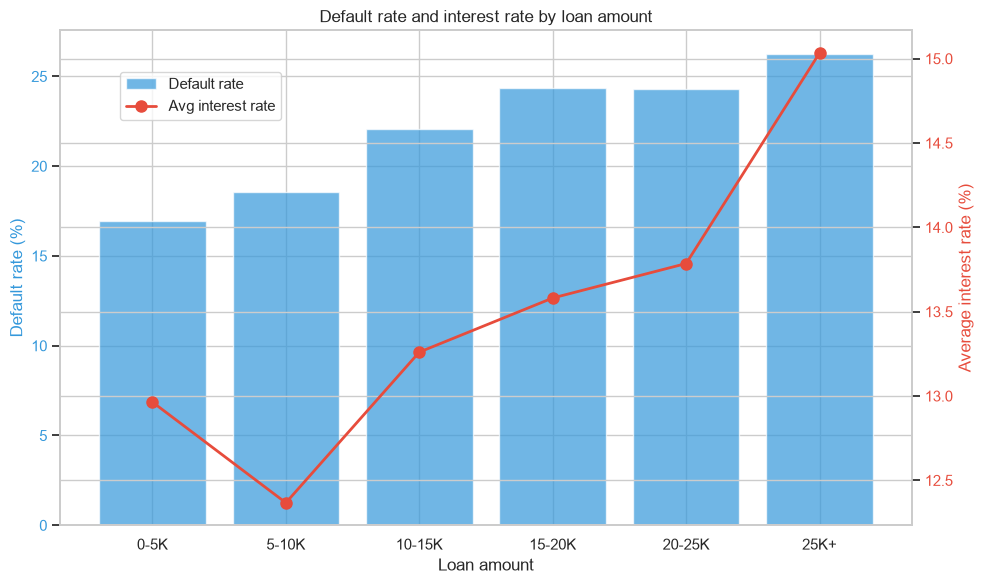

In [23]:
df["loan_amnt_bin"] = pd.cut(
    df["loan_amnt"],
    bins=[0, 5000, 10000, 15000, 20000, 25000, 40000],
    labels=["0-5K", "5-10K", "10-15K", "15-20K", "20-25K", "25K+"],
)

loan_amnt_default = df.groupby("loan_amnt_bin", observed=True).agg(
    total_loans=("target", "count"),
    default_rate=("target", "mean"),
    avg_int_rate=("int_rate", "mean"),
).reset_index()
loan_amnt_default["default_rate_pct"] = loan_amnt_default["default_rate"] * 100

fig, ax1 = plt.subplots(figsize=(10, 6))
x = range(len(loan_amnt_default))
ax1.bar(x, loan_amnt_default["default_rate_pct"],
        color="#3498db", alpha=0.7, label="Default rate")
ax1.set_xlabel("Loan amount")
ax1.set_ylabel("Default rate (%)", color="#3498db")
ax1.tick_params(axis="y", labelcolor="#3498db")
ax1.set_xticks(list(x))
ax1.set_xticklabels(loan_amnt_default["loan_amnt_bin"].astype(str))

ax2 = ax1.twinx()
ax2.plot(x, loan_amnt_default["avg_int_rate"], "o-", color="#e74c3c",
         linewidth=2, markersize=8, label="Avg interest rate")
ax2.set_ylabel("Average interest rate (%)", color="#e74c3c")
ax2.tick_params(axis="y", labelcolor="#e74c3c")

plt.title("Default rate and interest rate by loan amount")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.savefig("../images/11_loan_amount_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## One-screen summary of what EDA found

In [24]:
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Default rate by grade", "Default rate by FICO",
        "Interest rate distribution", "Loan amount distribution",
    ),
    specs=[[{"type": "bar"}, {"type": "bar"}],
           [{"type": "histogram"}, {"type": "histogram"}]],
)

fig.add_trace(
    go.Bar(x=grade_default["grade"], y=grade_default["default_rate_pct"],
           marker_color=grade_default["default_rate_pct"],
           marker_colorscale="RdYlGn_r", name="Grade"),
    row=1, col=1,
)
fig.add_trace(
    go.Bar(x=fico_default["fico_bin"].astype(str), y=fico_default["default_rate_pct"],
           marker_color=fico_default["default_rate_pct"],
           marker_colorscale="RdYlGn", name="FICO"),
    row=1, col=2,
)
fig.add_trace(
    go.Histogram(x=df[df["target"] == 0]["int_rate"], name="Fully Paid",
                 marker_color="#2ecc71", opacity=0.7),
    row=2, col=1,
)
fig.add_trace(
    go.Histogram(x=df[df["target"] == 1]["int_rate"], name="Default",
                 marker_color="#e74c3c", opacity=0.7),
    row=2, col=1,
)
fig.add_trace(
    go.Histogram(x=df[df["target"] == 0]["loan_amnt"], name="Fully Paid",
                 marker_color="#2ecc71", opacity=0.7, showlegend=False),
    row=2, col=2,
)
fig.add_trace(
    go.Histogram(x=df[df["target"] == 1]["loan_amnt"], name="Default",
                 marker_color="#e74c3c", opacity=0.7, showlegend=False),
    row=2, col=2,
)

fig.update_layout(height=700, title_text="Credit risk EDA dashboard", barmode="overlay")
fig.write_html("../images/12_eda_dashboard.html")
fig.show()

## Export per-segment summaries

Three summary CSVs — these go into Tableau later for a public-facing dashboard.

In [25]:
grade_default.to_csv("../data/processed/summary_by_grade.csv", index=False)
purpose_default.to_csv("../data/processed/summary_by_purpose.csv", index=False)
state_default.to_csv("../data/processed/summary_by_state.csv", index=False)
print("wrote 3 summary files to ../data/processed/")

wrote 3 summary files to ../data/processed/


## What I'm taking into the next notebook

Three things worth carrying forward explicitly, because they shape decisions in 03 and 04:

- **The class imbalance is ~20% / 80%.** In 04 I'll report PR-AUC alongside ROC-AUC, pick a threshold on expected cost rather than on the ROC elbow, and compare `class_weight='balanced'` logistic regression against SMOTE-resampled logistic regression. Raw accuracy stays off the scorecard.
- **`grade`, `int_rate`, and `fico_avg` carry overlapping signal.** On a linear model this is a case for L2 regularization; on a tree ensemble the model will handle it on its own, but feature importance across the three will be split in ways that are hard to interpret. I'll compute mutual information per-feature in 03 to get a feel for how much *independent* information each one adds.
- **Geography is noisy at the state level** for the smaller states. I'll either drop `addr_state`, or use target encoding with smoothing. One-hotting 50 states on this sample size would overfit.

And one caveat to repeat: everything above was computed on the full sampled dataset, not on a train split. The feature choices I just hinted at are *provisional* — I need to redo the per-segment default rates on just the training slice in 03 before I lock them in. That's the discipline I'd rather have gotten right the first time; now I know for next project.